# Telco Customer Churn: Exploratory Analysis

Which customers leave, and why? This notebook explores the IBM Telco dataset (7,043 customers) before modelling in `src/churn/train.py`.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from src.churn.data import load
from src.churn.features import add_features
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = add_features(load())
print(df.shape)
df.head()

(7043, 23)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,num_services,avg_monthly_spend,tenure_band
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1,29.850000,0-6m
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.50,0,2,55.573529,2-4y
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,2,54.075000,0-6m
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,3,40.905556,2-4y
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0,75.825000,0-6m


## 1. How big is the problem?

In [2]:
rate = df['Churn'].mean()
print(f'Churn rate: {rate:.1%}  ({df.Churn.sum():,} of {len(df):,} customers)')
print(f"Monthly revenue lost to churners: ${df.loc[df.Churn==1, 'MonthlyCharges'].sum():,.0f}")

Churn rate: 26.5%  (1,869 of 7,043 customers)
Monthly revenue lost to churners: $139,131


About a quarter of customers churn. The classes are imbalanced, so plain accuracy would be misleading. Models are judged on ROC-AUC, PR-AUC and F1 instead.

## 2. Contract type is the strongest signal

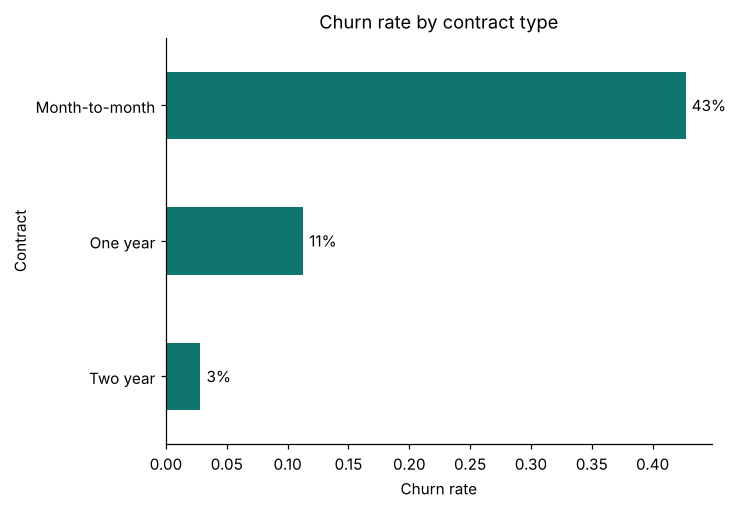

In [3]:
ax = df.groupby('Contract')['Churn'].mean().sort_values().plot.barh(color='#0f766e')
ax.set_xlabel('Churn rate'); ax.set_title('Churn rate by contract type')
for i, v in enumerate(df.groupby('Contract')['Churn'].mean().sort_values()): ax.text(v + .005, i, f'{v:.0%}', va='center')
plt.show()

## 3. New customers are the riskiest

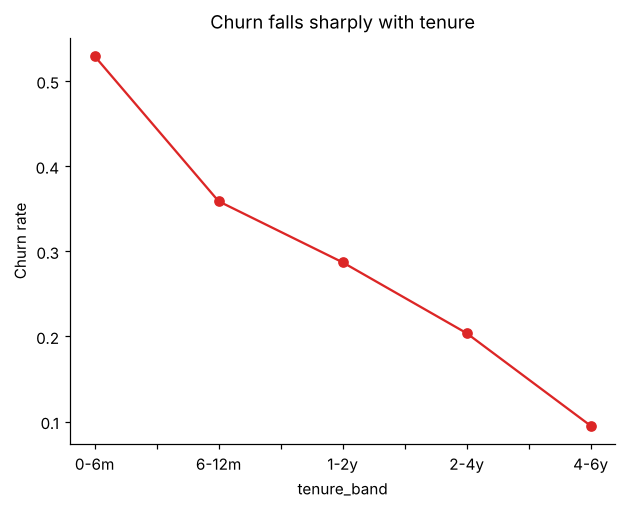

In [4]:
t = df.groupby('tenure_band', observed=True)['Churn'].mean().reindex(['0-6m','6-12m','1-2y','2-4y','4-6y'])
ax = t.plot(marker='o', color='#dc2626'); ax.set_ylabel('Churn rate'); ax.set_title('Churn falls sharply with tenure')
plt.show()

## 4. Price, payment method and add-on services

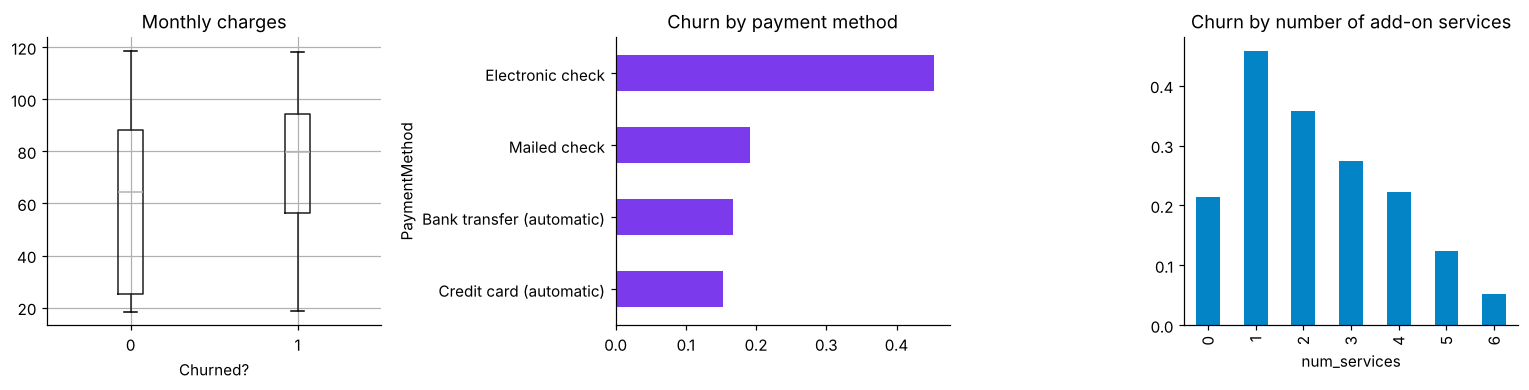

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
df.boxplot(column='MonthlyCharges', by='Churn', ax=axes[0]); axes[0].set_title('Monthly charges'); axes[0].set_xlabel('Churned?')
df.groupby('PaymentMethod')['Churn'].mean().sort_values().plot.barh(ax=axes[1], color='#7c3aed'); axes[1].set_title('Churn by payment method')
df.groupby('num_services')['Churn'].mean().plot.bar(ax=axes[2], color='#0284c7'); axes[2].set_title('Churn by number of add-on services')
plt.suptitle(''); plt.tight_layout(); plt.show()

## 5. Takeaways for the business

- **Month-to-month contracts** churn far more than one- or two-year contracts. Discounts for upgrading to annual plans are the biggest lever.
- **The first six months** are critical, so onboarding and early check-ins matter most.
- **Electronic-check** payers churn the most. Nudging them to autopay could reduce friction.
- **More add-on services, less churn**: bundles such as security and tech support increase stickiness.

Next: `python -m src.churn.train` compares three models and saves the best one for the Streamlit app.